# 📈 Sales Forecasting (Time Series Basics)

**Goal:** predict future daily sales of a store using only past sales.

This is a **time series** problem — the order of the data matters.
Each row is one day, and tomorrow depends on what happened before.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

## Step 1: Load the data

Two columns only: `Date` and `Sales`. We parse dates so pandas understands time.

In [2]:
df = pd.read_csv("data/daily_sales.csv", parse_dates=["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print(df.head())
print("\nShape:", df.shape)
print("From", df["Date"].min().date(), "to", df["Date"].max().date())

        Date  Sales
0 2024-01-01  102.4
1 2024-01-02   91.8
2 2024-01-03  106.2
3 2024-01-04  107.8
4 2024-01-05   84.7

Shape: (1095, 2)
From 2024-01-01 to 2026-12-30


## Step 2: Plot the full series

Always look first. You can already see: sales grow over time, and there is a weekly up-down pattern.

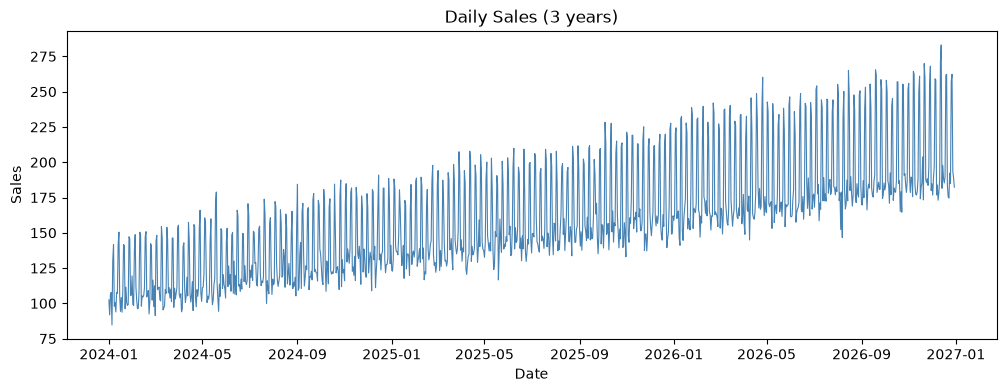

In [3]:
plt.figure(figsize=(12, 4))
plt.plot(df["Date"], df["Sales"], linewidth=0.8, color="steelblue")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Daily Sales (3 years)")
plt.show()

## Step 3: Find the trend — 30-day rolling mean

Daily sales are noisy. A **rolling mean** smooths the noise so the trend becomes visible:
upward over the three years. 📈

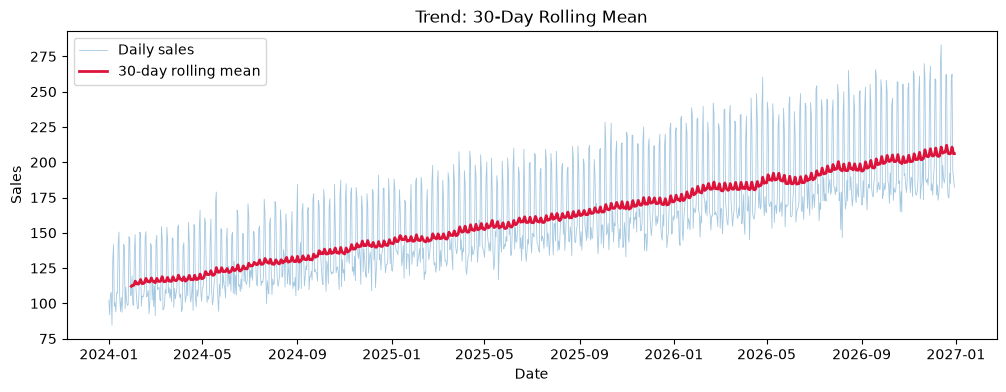

In [4]:
df["Roll30"] = df["Sales"].rolling(window=30).mean()

plt.figure(figsize=(12, 4))
plt.plot(df["Date"], df["Sales"], linewidth=0.6, alpha=0.4, label="Daily sales")
plt.plot(df["Date"], df["Roll30"], linewidth=2, color="crimson", label="30-day rolling mean")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Trend: 30-Day Rolling Mean")
plt.legend()
plt.show()

## Step 4: Find the seasonality — sales by weekday

Group by day of the week. Weekends (Sat, Sun) are clearly the busiest — about 1.4x a weekday.
This weekly pattern is called **seasonality**. 🗓️

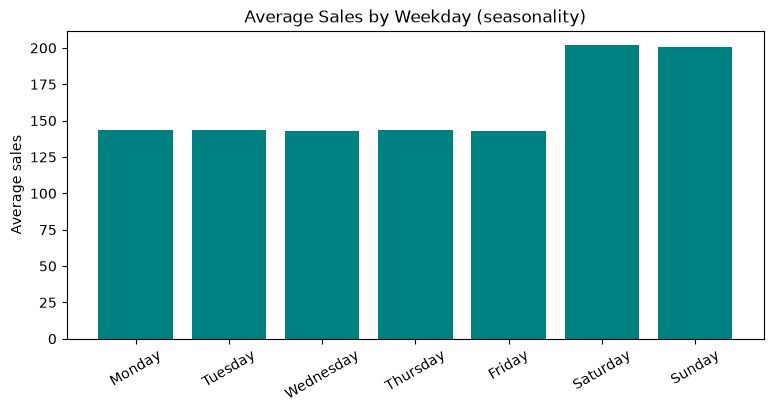

Weekday
Monday       143.9
Tuesday      143.7
Wednesday    143.0
Thursday     143.6
Friday       143.1
Saturday     201.7
Sunday       200.9
Name: Sales, dtype: float64


In [5]:
df["Weekday"] = df["Date"].dt.day_name()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = df.groupby("Weekday")["Sales"].mean().reindex(order)

plt.figure(figsize=(9, 4))
plt.bar(by_day.index, by_day.values, color="teal")
plt.xticks(rotation=30)
plt.ylabel("Average sales")
plt.title("Average Sales by Weekday (seasonality)")
plt.show()
print(by_day.round(1))

## Step 5: Time-based train/test split ⚠️

**NEVER shuffle a time series!** In real life you only know the *past* when predicting the *future*.
So: train on the first 1035 days, test on the **last 60 days** — the model never sees the future during training.

In [6]:
TEST_DAYS = 60
train = df.iloc[:-TEST_DAYS].copy()
test = df.iloc[-TEST_DAYS:].copy()

print("Train:", len(train), "days | Test:", len(test), "days")
print("Train ends:", train["Date"].max().date(), "| Test starts:", test["Date"].min().date())

Train: 1035 days | Test: 60 days
Train ends: 2026-10-31 | Test starts: 2026-11-01


## Step 6: Two simple baselines

Before fancy models, always try simple baselines:

- **Baseline 1 — Naive:** predict every test day = the *last* train value. ("Tomorrow will be like today.")
- **Baseline 2 — 7-day moving average:** predict every test day = average of the last 7 train days. (Captures the weekly rhythm.)

We score both with **MAE** (mean absolute error) — average |actual − predicted|. Lower is better.

In [7]:
# Baseline 1: naive — repeat last train value
last_value = train["Sales"].iloc[-1]
naive_pred = np.full(len(test), last_value)

# Baseline 2: 7-day moving average of the train tail
ma7 = train["Sales"].iloc[-7:].mean()
ma7_pred = np.full(len(test), ma7)

def mae(actual, predicted):
    return np.mean(np.abs(actual - predicted))

mae_naive = mae(test["Sales"].values, naive_pred)
mae_ma7 = mae(test["Sales"].values, ma7_pred)

print(f"Baseline 1 (naive) MAE:        {mae_naive:.2f}")
print(f"Baseline 2 (7-day average) MAE: {mae_ma7:.2f}")
print(f"\nWinner: {'7-day average' if mae_ma7 < mae_naive else 'naive'} 🏆")

Baseline 1 (naive) MAE:        51.18
Baseline 2 (7-day average) MAE: 31.14

Winner: 7-day average 🏆


## Step 7: Actual vs forecasts 📊

The 7-day average wins — because it captures the weekly seasonality, while the naive forecast just repeats one noisy day.

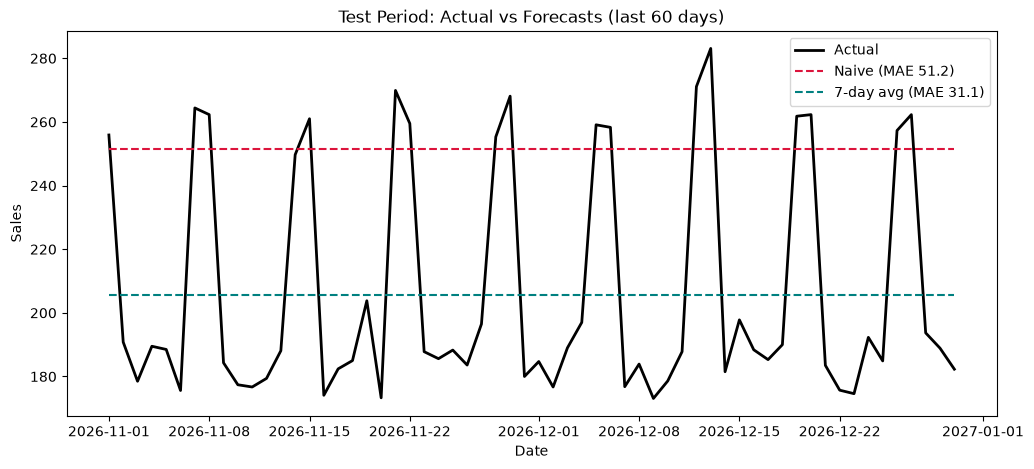

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(test["Date"], test["Sales"].values, label="Actual", linewidth=2, color="black")
plt.plot(test["Date"], naive_pred, label=f"Naive (MAE {mae_naive:.1f})",
         linestyle="--", color="crimson")
plt.plot(test["Date"], ma7_pred, label=f"7-day avg (MAE {mae_ma7:.1f})",
         linestyle="--", color="teal")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Test Period: Actual vs Forecasts (last 60 days)")
plt.legend()
plt.show()

## Key takeaway ✅

1. **Plot first** — trend and seasonality were visible before any model.
2. **Never shuffle time series** — always split by time (past → future).
3. **Start with baselines** — a 7-day average beat the naive forecast here. Any fancier model (ARIMA, Prophet, LSTM) must beat *these* numbers to be worth it.